In [1]:
import os
import random
import subprocess
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import keras
from keras import layers

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

np.random.seed(42)
random.seed(42)
keras.utils.set_random_seed(42)
warnings.filterwarnings("ignore")

print("Keras version:", keras.__version__)

c:\Users\suhan\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\suhan\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Keras version: 3.15.1


In [2]:
#3. Load data
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
import kagglehub

DATA_DIR = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Dataset path:", DATA_DIR)
print(os.listdir(DATA_DIR))

IMG_SIZE = 32
NUM_CLASSES = 43

Dataset path: C:\Users\suhan\.cache\kagglehub\datasets\meowmeowmeowmeowmeow\gtsrb-german-traffic-sign\versions\1
['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


In [3]:
def load_img(path):
    with Image.open(path) as img:
        return np.array(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))


def load_train(train_dir):
    paths, labels, groups = [], [], []
    for class_id in range(NUM_CLASSES):
        class_dir = os.path.join(train_dir, str(class_id))
        for file_name in os.listdir(class_dir):
            if not file_name.lower().endswith((".png", ".jpg", ".jpeg", ".ppm")):
                continue
            paths.append(os.path.join(class_dir, file_name))
            labels.append(class_id)
            # file name format: <class>_<track>_<frame>.png -> frames of one track are near-identical
            track_id = file_name.split("_")[1]
            groups.append(f"{class_id}_{track_id}")
    with ThreadPoolExecutor(max_workers=16) as ex:
        images = list(tqdm(ex.map(load_img, paths), total=len(paths), desc="Train"))
    return np.array(images), np.array(labels), np.array(groups)


def load_test(data_dir):
    df = pd.read_csv(os.path.join(data_dir, "Test.csv"))
    paths = [os.path.join(data_dir, p) for p in df["Path"]]
    with ThreadPoolExecutor(max_workers=16) as ex:
        images = list(tqdm(ex.map(load_img, paths), total=len(paths), desc="Test"))
    return np.array(images), df["ClassId"].values


CACHE = "/content/gtsrb_data.npz" if os.path.exists("/content") else "gtsrb_data.npz"

if os.path.exists(CACHE):
    d = np.load(CACHE, allow_pickle=True)
    X_train_raw, y_train_all, groups = d["X_train"], d["y_train"], d["groups"]
    X_test_raw, y_test = d["X_test"], d["y_test"]
    print("Loaded from cache:", CACHE)
else:
    X_train_raw, y_train_all, groups = load_train(os.path.join(DATA_DIR, "Train"))
    X_test_raw, y_test = load_test(DATA_DIR)
    np.savez_compressed(
        CACHE,
        X_train=X_train_raw, y_train=y_train_all, groups=groups,
        X_test=X_test_raw, y_test=y_test,
    )
    print("Saved cache:", CACHE)

print("X_train_raw shape:", X_train_raw.shape)
print("y_train_all shape:", y_train_all.shape)
print("X_test_raw shape:", X_test_raw.shape)
print("y_test shape:", y_test.shape)
print("Number of tracks:", len(np.unique(groups)))

Test: 100%|██████████| 12630/12630 [00:11<00:00, 1117.24it/s]


Saved cache: gtsrb_data.npz
X_train_raw shape: (39209, 32, 32, 3)
y_train_all shape: (39209,)
X_test_raw shape: (12630, 32, 32, 3)
y_test shape: (12630,)
Number of tracks: 1307


In [4]:
class_names = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)", "Speed limit (60km/h)",
    "Speed limit (70km/h)", "Speed limit (80km/h)", "End of speed limit (80km/h)", "Speed limit (100km/h)",
    "Speed limit (120km/h)", "No passing", "No passing for vehicles over 3.5 tons",
    "Right-of-way at next intersection", "Priority road", "Yield", "Stop", "No vehicles",
    "Vehicles over 3.5 tons prohibited", "No entry", "General caution", "Dangerous curve to the left",
    "Dangerous curve to the right", "Double curve", "Bumpy road", "Slippery road",
    "Road narrows on the right", "Road work", "Traffic signals", "Pedestrians", "Children crossing",
    "Bicycles crossing", "Beware of ice/snow", "Wild animals crossing", "End of all speed and passing limits",
    "Turn right ahead", "Turn left ahead", "Ahead only", "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory", "End of no passing",
    "End of no passing by vehicles over 3.5 tons",
]

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

0: Speed limit (20km/h)
1: Speed limit (30km/h)
2: Speed limit (50km/h)
3: Speed limit (60km/h)
4: Speed limit (70km/h)
5: Speed limit (80km/h)
6: End of speed limit (80km/h)
7: Speed limit (100km/h)
8: Speed limit (120km/h)
9: No passing
10: No passing for vehicles over 3.5 tons
11: Right-of-way at next intersection
12: Priority road
13: Yield
14: Stop
15: No vehicles
16: Vehicles over 3.5 tons prohibited
17: No entry
18: General caution
19: Dangerous curve to the left
20: Dangerous curve to the right
21: Double curve
22: Bumpy road
23: Slippery road
24: Road narrows on the right
25: Road work
26: Traffic signals
27: Pedestrians
28: Children crossing
29: Bicycles crossing
30: Beware of ice/snow
31: Wild animals crossing
32: End of all speed and passing limits
33: Turn right ahead
34: Turn left ahead
35: Ahead only
36: Go straight or right
37: Go straight or left
38: Keep right
39: Keep left
40: Roundabout mandatory
41: End of no passing
42: End of no passing by vehicles over 3.5 tons


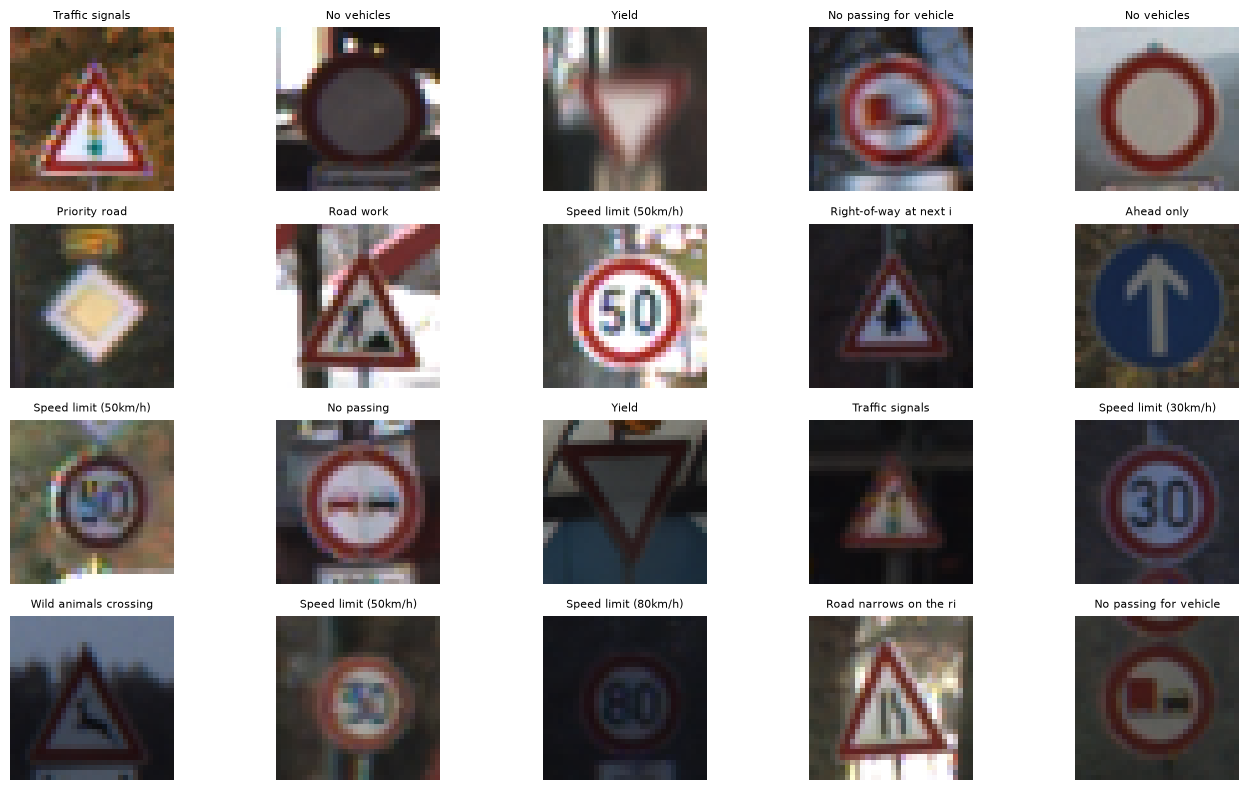

In [5]:
#5. EDA: sample img
plt.figure(figsize=(14, 8))
random_idx = np.random.choice(len(X_train_raw), 20, replace=False)
for plot_no, idx in enumerate(random_idx):
    plt.subplot(4, 5, plot_no + 1)
    plt.imshow(X_train_raw[idx])
    plt.title(class_names[y_train_all[idx]][:22], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

,Label,Class,Count
0,0,Speed limit (20km/h),210
1,1,Speed limit (30km/h),2220
2,2,Speed limit (50km/h),2250
3,3,Speed limit (60km/h),1410
4,4,Speed limit (70km/h),1980
5,5,Speed limit (80km/h),1860
6,6,End of speed limit (80km/h),420
7,7,Speed limit (100km/h),1440
8,8,Speed limit (120km/h),1410
9,9,No passing,1470


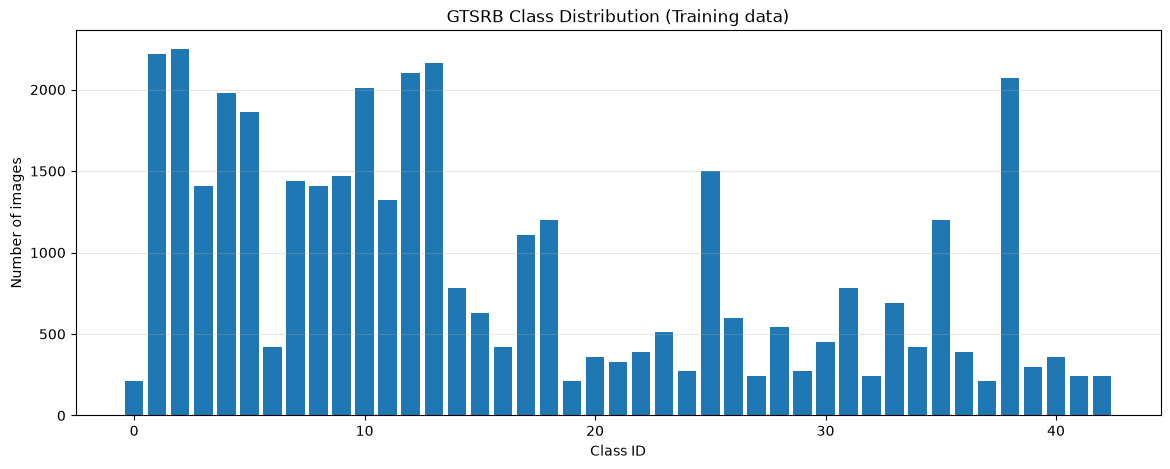

In [6]:
# Classs distibution - EDA
unique_labels, counts = np.unique(y_train_all, return_counts=True)
class_distribution = pd.DataFrame({
    "Label": unique_labels,
    "Class": [class_names[i] for i in unique_labels],
    "Count": counts,
})
display(class_distribution)

plt.figure(figsize=(14, 5))
plt.bar(class_distribution["Label"], class_distribution["Count"])
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.title("GTSRB Class Distribution (Training data)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [7]:
sample_idx = np.random.choice(len(X_train_raw), 2000, replace=False)
duplicate_check = X_train_raw[sample_idx].reshape(2000, -1)

unique_rows = np.unique(duplicate_check, axis=0)

print("Images checked:", len(duplicate_check))
print("Unique rows:", len(unique_rows))
print("Duplicates in this sample:", len(duplicate_check) - len(unique_rows))

Images checked: 2000
Unique rows: 2000
Duplicates in this sample: 0


In [8]:
# 8. Normalisation
x_train_all = X_train_raw.astype("float32") / 255.0
x_test = X_test_raw.astype("float32") / 255.0

print("Data type:", x_train_all.dtype)
print("Minimum pixel value:", x_train_all.min())
print("Maximum pixel value:", x_train_all.max())
print("NaN values in train:", np.isnan(x_train_all).sum())
print("NaN values in test:", np.isnan(x_test).sum())
print("Infinite values in train:", np.isinf(x_train_all).sum())
print("Infinite values in test:", np.isinf(x_test).sum())

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
NaN values in train: 0
NaN values in test: 0
Infinite values in train: 0
Infinite values in test: 0


In [9]:
#9. Track-wise train/validation split (no leakage between frames of one sign)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, val_idx = next(gss.split(x_train_all, y_train_all, groups))

x_train, y_train = x_train_all[train_idx], y_train_all[train_idx]
x_val, y_val = x_train_all[val_idx], y_train_all[val_idx]

assert len(set(groups[train_idx]) & set(groups[val_idx])) == 0, "Track leakage!"

print("Training  :", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test      :", x_test.shape, y_test.shape)
print("Classes in val:", len(np.unique(y_val)), "/", NUM_CLASSES)

Training  : (31349, 32, 32, 3) (31349,)
Validation: (7860, 32, 32, 3) (7860,)
Test      : (12630, 32, 32, 3) (12630,)
Classes in val: 41 / 43


In [10]:
#  10. ANN baseline
ann_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="ann")

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
ann_model.summary()

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 825,131 (3.15 MB)

 Trainable params: 825,131 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#11. Train ANN
history_ann = ann_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1,
)

Epoch 1/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.3721 - loss: 2.3033 - val_accuracy: 0.6106 - val_loss: 1.5409
Epoch 2/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6131 - loss: 1.2883 - val_accuracy: 0.6955 - val_loss: 1.1506
Epoch 3/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7143 - loss: 0.9510 - val_accuracy: 0.7752 - val_loss: 0.8336
Epoch 4/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7519 - loss: 0.8171 - val_accuracy: 0.8055 - val_loss: 0.7074
Epoch 5/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7784 - loss: 0.7255 - val_accuracy: 0.8238 - val_loss: 0.6858
Epoch 6/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8015 - loss: 0.6509 - val_accuracy: 0.8324 - val_loss: 0.6283
Epoch 7/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8076 - loss: 0.6289 - val_accuracy: 0.8491 - val_loss: 0.5849
Epoch 8/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8172 - loss: 0.5960 - val_accura

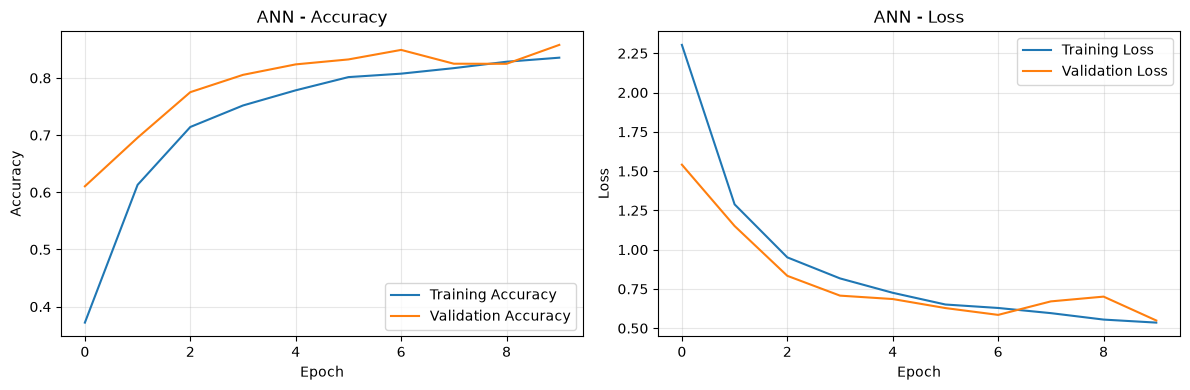

In [12]:
# 12. ANN curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history["accuracy"], label="Training Accuracy")
plt.plot(history_ann.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("ANN - Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_ann.history["loss"], label="Training Loss")
plt.plot(history_ann.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("ANN - Loss")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

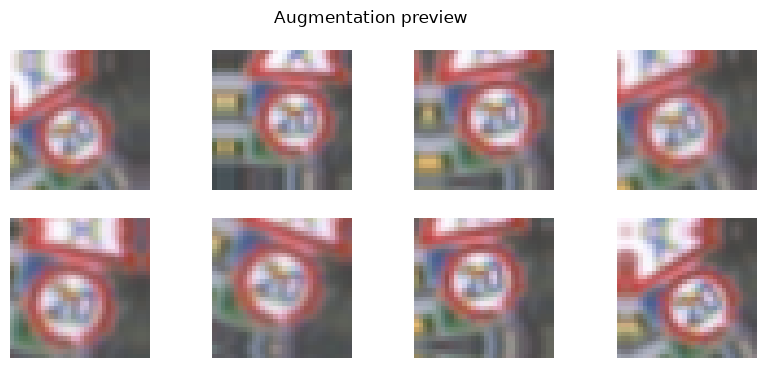

In [13]:
#13. Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
], name="data_augmentation")


# Preview augmentation
plt.figure(figsize=(10, 4))
sample = x_train[:1]
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(data_augmentation(sample, training=True)[0])
    plt.axis("off")
plt.suptitle("Augmentation preview")
plt.show()


In [15]:
#14. CNN (augmentation is now part of the model, active only during training)
cnn_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),  # fixed: was Dense
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="cnn")
cnn_model.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,963 (1.38 MB)

 Trainable params: 361,515 (1.38 MB)

 Non-trainable params: 448 (1.75 KB)

In [16]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [17]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
]

In [19]:
history_cnn = cnn_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks = callbacks,
    verbose=1,
)

Epoch 1/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 28s 51ms/step - accuracy: 0.3897 - loss: 2.1073 - val_accuracy: 0.4522 - val_loss: 1.7038
Epoch 2/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.6994 - loss: 0.9056 - val_accuracy: 0.7921 - val_loss: 0.5985
Epoch 3/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 26s 53ms/step - accuracy: 0.8452 - loss: 0.4697 - val_accuracy: 0.8658 - val_loss: 0.4398
Epoch 4/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.9034 - loss: 0.2984 - val_accuracy: 0.8995 - val_loss: 0.3057
Epoch 5/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.9275 - loss: 0.2272 - val_accuracy: 0.9130 - val_loss: 0.2729
Epoch 6/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.9418 - loss: 0.1800 - val_accuracy: 0.9284 - val_loss: 0.2213
Epoch 7/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 31s 64ms/step - accuracy: 0.9543 - loss: 0.1484 - val_accuracy: 0.9226 - val_loss: 0.2499
Epoch 8/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 34s 70ms/step - accuracy: 0.9547 - loss: 0.1406 - 

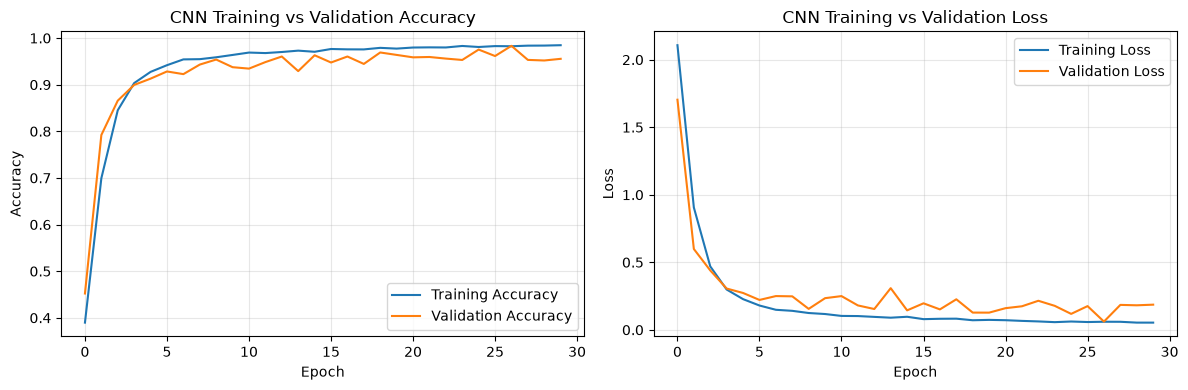

In [20]:
#16. CNN curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("CNN Training vs Validation Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("CNN Training vs Validation Loss")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
#17. Final evaluation on the held-out TEST set (report these numbers)
ann_probs = ann_model.predict(x_test, verbose=0)
cnn_probs = cnn_model.predict(x_test, verbose=0)

y_pred_ann = np.argmax(ann_probs, axis=1)
y_pred_cnn = np.argmax(cnn_probs, axis=1)

acc_ann = accuracy_score(y_test, y_pred_ann)
acc_cnn = accuracy_score(y_test, y_pred_cnn)

val_acc_cnn = cnn_model.evaluate(x_val, y_val, verbose=0)[1]

print("ANN test accuracy:", round(acc_ann, 4))
print("CNN validation accuracy:", round(val_acc_cnn, 4))
print("CNN test accuracy:", round(acc_cnn, 4))

ANN test accuracy: 0.8317
CNN validation accuracy: 0.9833
CNN test accuracy: 0.9601


In [22]:
#18. Classification report
print(classification_report(
    y_test, y_pred_cnn,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
))


                                             precision    recall  f1-score   support

                       Speed limit (20km/h)       0.92      0.98      0.95        60
                       Speed limit (30km/h)       0.98      1.00      0.99       720
                       Speed limit (50km/h)       0.97      0.99      0.98       750
                       Speed limit (60km/h)       0.95      0.97      0.96       450
                       Speed limit (70km/h)       0.98      0.97      0.97       660
                       Speed limit (80km/h)       0.97      0.94      0.96       630
                End of speed limit (80km/h)       0.94      0.97      0.96       150
                      Speed limit (100km/h)       0.98      0.97      0.97       450
                      Speed limit (120km/h)       0.98      0.96      0.97       450
                                 No passing       1.00      0.99      1.00       480
      No passing for vehicles over 3.5 tons       1.00      1.00

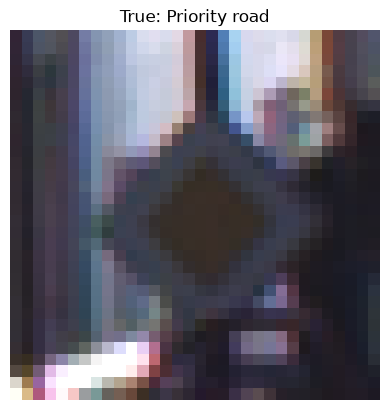

Top 3 Predictions:

Priority road -> 100.00 %
End of no passing by vehicles over 3.5 tons -> 0.00 %
Speed limit (60km/h) -> 0.00 %


In [23]:
#19. Top-3 predictions for one test image
sample_index = 10
probabilities = cnn_probs[sample_index]
top3_indices = np.argsort(probabilities)[-3:][::-1]

plt.imshow(x_test[sample_index])
plt.axis("off")
plt.title("True: " + class_names[y_test[sample_index]])
plt.show()

print("Top 3 Predictions:\n")
for idx in top3_indices:
    print(f"{class_names[idx]} -> {probabilities[idx] * 100:.2f} %")

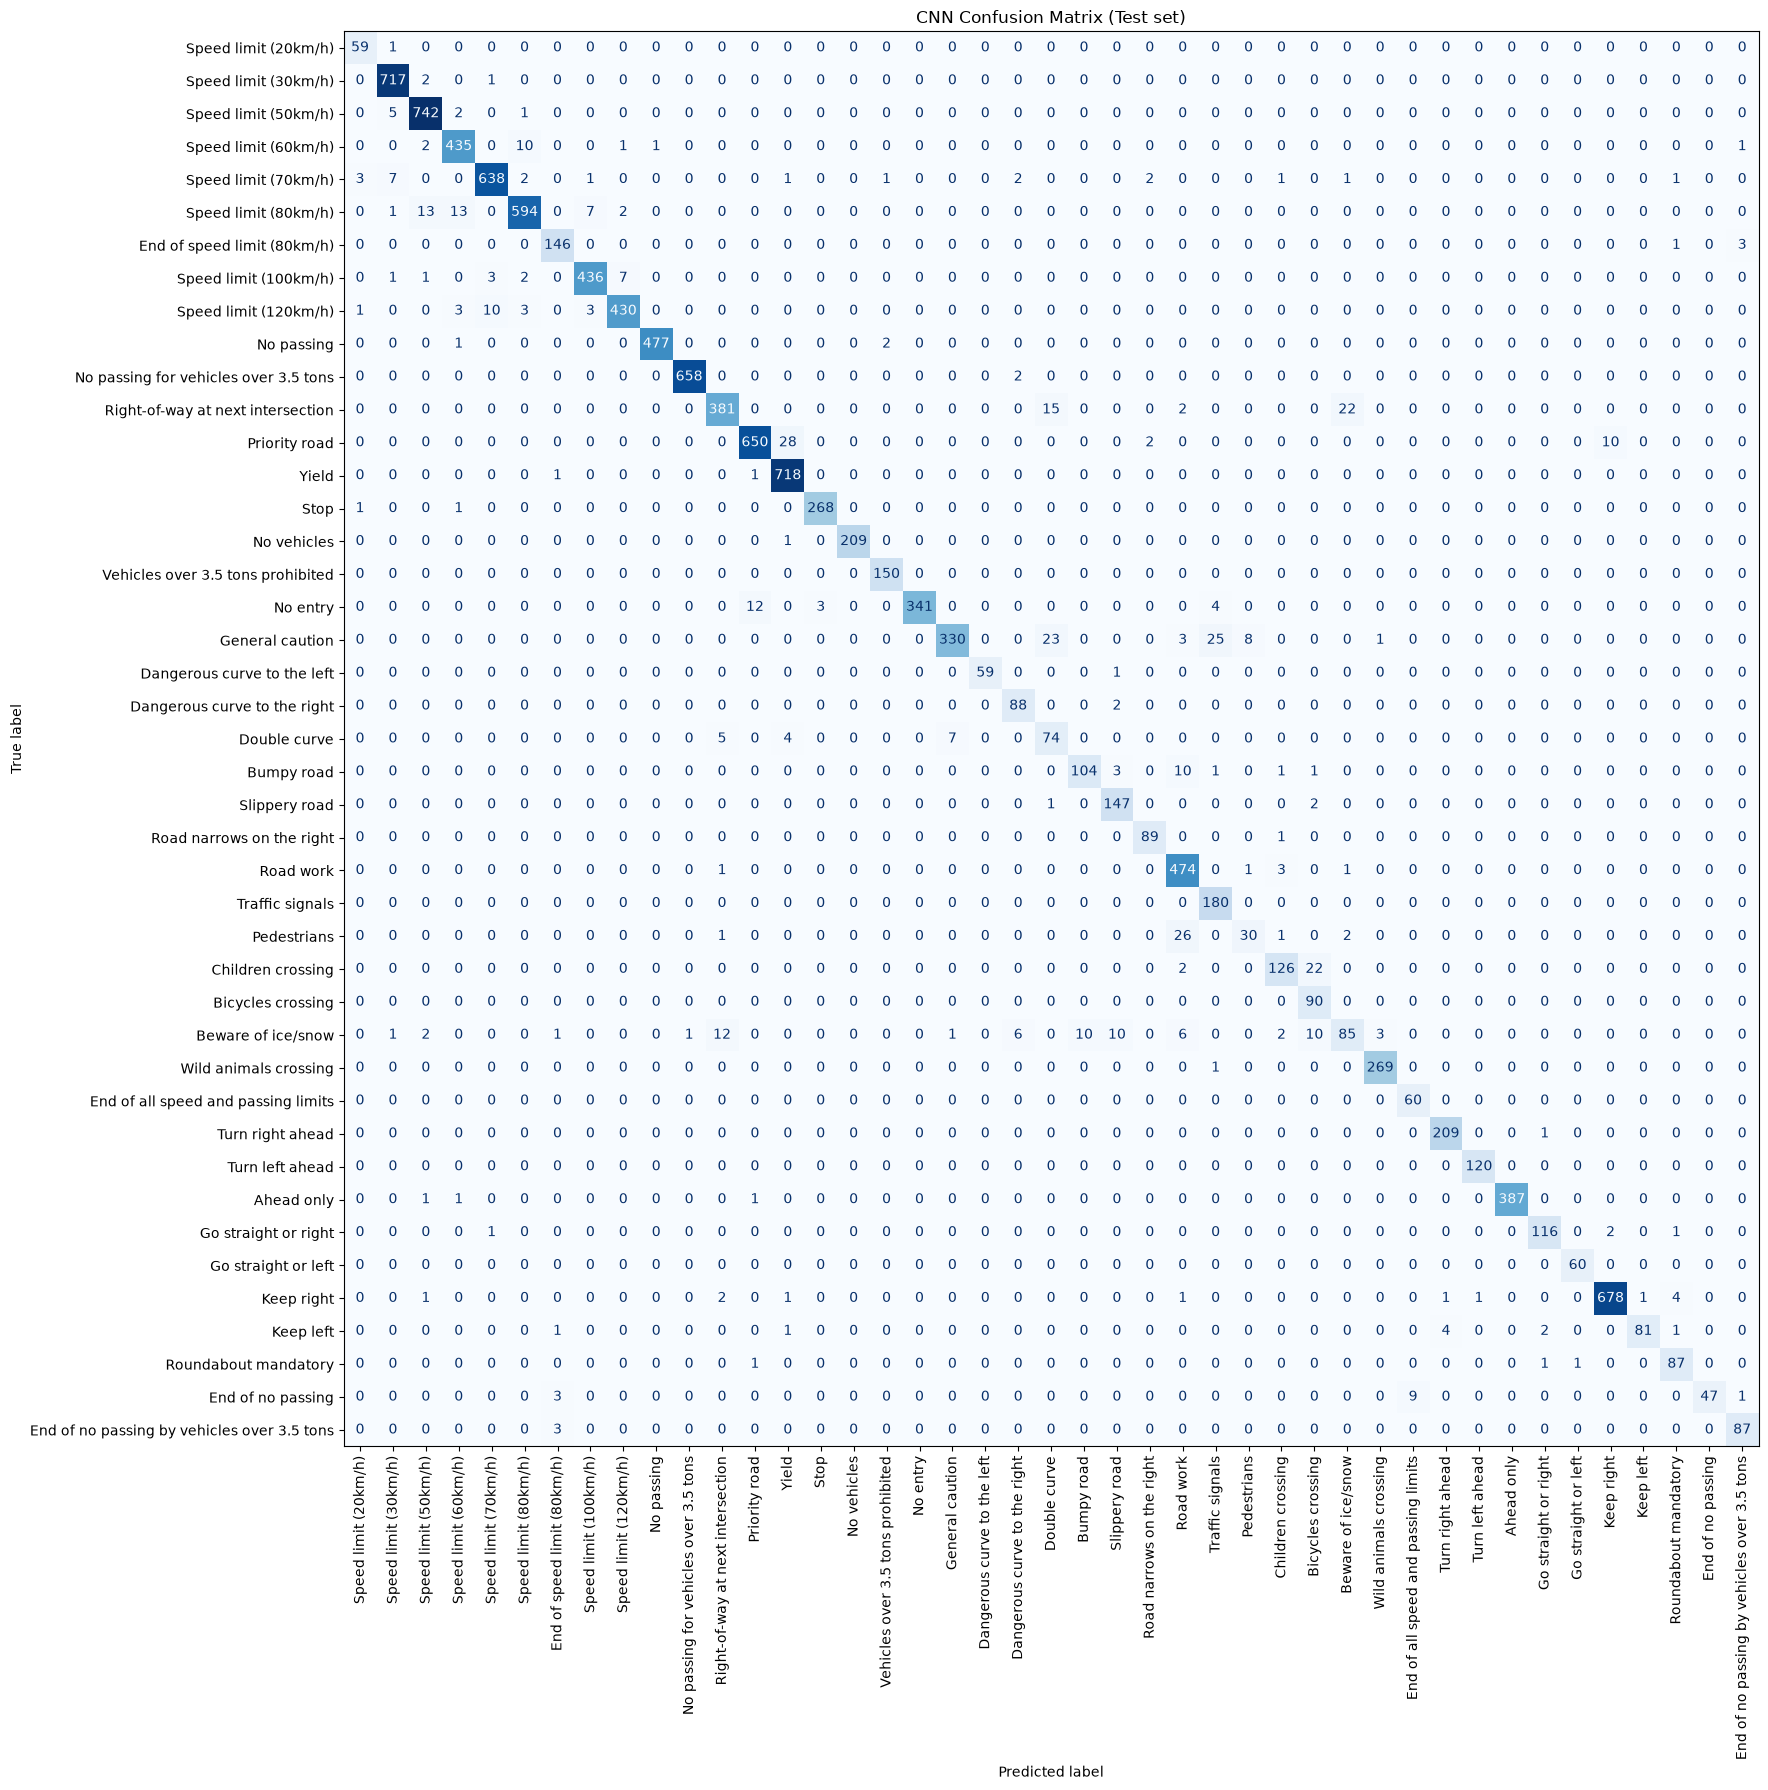

In [24]:
#20. Confusion matrix (counts)
cm = confusion_matrix(y_test, y_pred_cnn, labels=list(range(NUM_CLASSES)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("CNN Confusion Matrix (Test set)")
plt.tight_layout()
plt.show()

In [25]:
#22. Per-class accuracy: weakest classes
per_class_acc = cm.diagonal() / cm.sum(axis=1)
weak = pd.DataFrame({
    "Class": class_names,
    "Test images": cm.sum(axis=1),
    "Accuracy": per_class_acc.round(4),
}).sort_values("Accuracy").head(10)
display(weak)

,Class,Test images,Accuracy
27,Pedestrians,60,0.5000
30,Beware of ice/snow,150,0.5667
41,End of no passing,60,0.7833
21,Double curve,90,0.8222
28,Children crossing,150,0.8400
18,General caution,390,0.8462
22,Bumpy road,120,0.8667
39,Keep left,90,0.9000
11,Right-of-way at next intersection,420,0.9071
12,Priority road,690,0.9420


Wrong predictions: 504 out of 12630


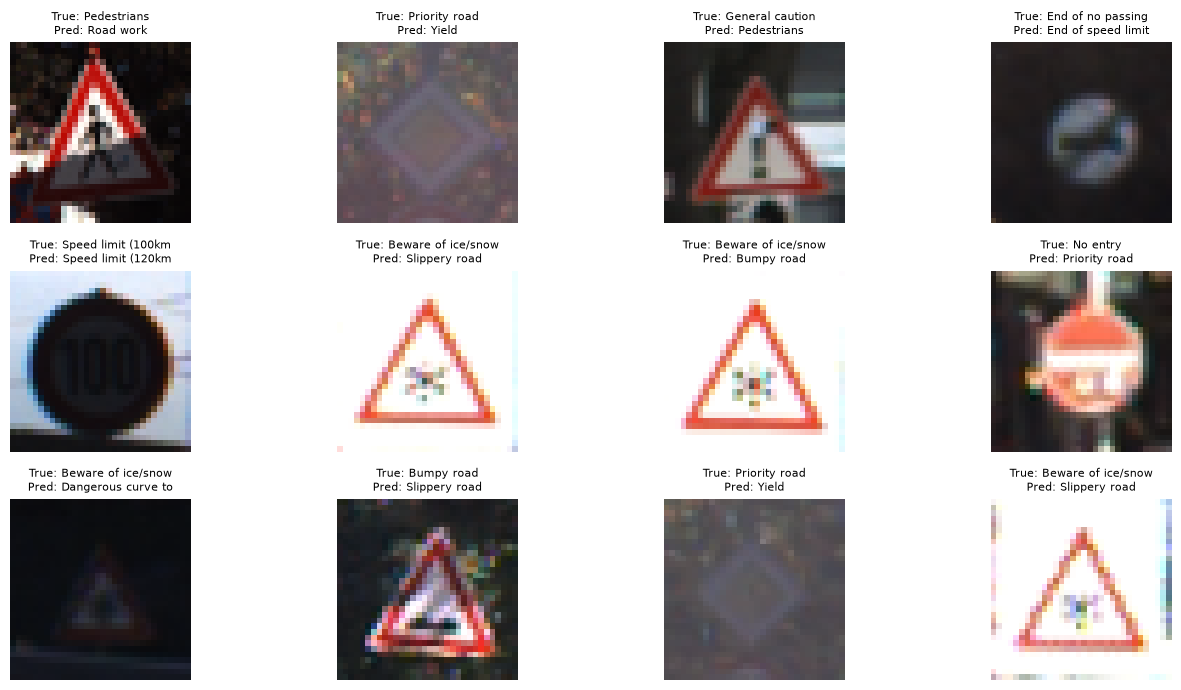

In [26]:
#23. Wrong predictions
wrong_idx = np.where(y_pred_cnn != y_test)[0]
print("Wrong predictions:", len(wrong_idx), "out of", len(y_test))

if len(wrong_idx) > 0:
    show_idx = np.random.choice(wrong_idx, min(12, len(wrong_idx)), replace=False)
    plt.figure(figsize=(14, 7))
    for plot_no, idx in enumerate(show_idx):
        plt.subplot(3, 4, plot_no + 1)
        plt.imshow(x_test[idx])
        plt.title(
            f"True: {class_names[y_test[idx]][:18]}\nPred: {class_names[y_pred_cnn[idx]][:18]}",
            fontsize=8,
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()

,Model,Test Accuracy
0,ANN,0.8317
1,CNN,0.9601


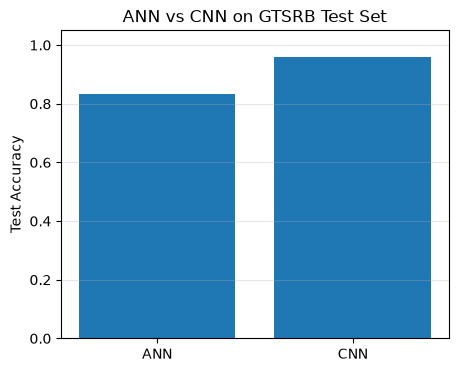

In [27]:
#24. ANN vs CNN comparison
comparison_df = pd.DataFrame({
    "Model": ["ANN", "CNN"],
    "Test Accuracy": [round(acc_ann, 4), round(acc_cnn, 4)],
})
display(comparison_df)

plt.figure(figsize=(5, 4))
plt.bar(comparison_df["Model"], comparison_df["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.title("ANN vs CNN on GTSRB Test Set")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [28]:
#25. Save final model
cnn_model.save("gtsrb_cnn.keras")
print("Model saved: gtsrb_cnn.keras")

Model saved: gtsrb_cnn.keras



---
# Part 2: Classical Machine Learning (HOG + SVM)

So far this notebook used **ANN** (raw pixels) and **CNN** (learned features). Here we solve the *same* problem with **classical machine learning**: features are hand-crafted (HOG for shape, HSV histogram for colour) and then classified with an **SVM**.

The data, the track-wise train/validation split and the test set are **reused from above**, so the comparison with ANN and CNN is fair.


### ML imports

In [30]:
import os, random, subprocess, sys, time, warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from joblib import Parallel, delayed

from skimage.feature import hog
from skimage.color import rgb2gray, rgb2hsv
from skimage import exposure

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

np.random.seed(42)
random.seed(42)
warnings.filterwarnings("ignore")

### Reuse data and the track-wise split from above

In [31]:

# X_train_raw, y_train_all, groups, X_test_raw, y_test, train_idx, val_idx
Xtr_img, y_train = X_train_raw[train_idx], y_train_all[train_idx]
Xva_img, y_val   = X_train_raw[val_idx],   y_train_all[val_idx]
Xte_img          = X_test_raw

assert len(set(groups[train_idx]) & set(groups[val_idx])) == 0, "Track leakage!"
print("Training  :", Xtr_img.shape)
print("Validation:", Xva_img.shape)
print("Test      :", Xte_img.shape)


Training  : (31349, 32, 32, 3)
Validation: (7860, 32, 32, 3)
Test      : (12630, 32, 32, 3)


In [32]:
# feature Extraction
# --- HOG + colour histogram (HSV)
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(4, 4), cells_per_block=(2, 2),
                  block_norm="L2-Hys")

def hog_feature(img):
    gray = rgb2gray(img)                       # 32x32x3 -> 32x32, values 0-1
    gray = exposure.equalize_adapthist(gray)   # CLAHE: fix uneven lighting
    return hog(gray, **HOG_PARAMS)

def color_feature(img, bins=8):
    hsv = rgb2hsv(img)                         # H, S, V each in 0-1
    feats = []
    for ch in range(3):
        h, _ = np.histogram(hsv[..., ch], bins=bins, range=(0, 1), density=True)
        feats.append(h)
    return np.concatenate(feats)               # 3 * 8 = 24 numbers

def extract(images, which="hog+color"):
    def one(img):
        parts = []
        if "hog" in which:   parts.append(hog_feature(img))
        if "color" in which: parts.append(color_feature(img))
        return np.concatenate(parts)
    out = Parallel(n_jobs=-1)(delayed(one)(im) for im in tqdm(images, desc=which))
    return np.array(out, dtype=np.float32)

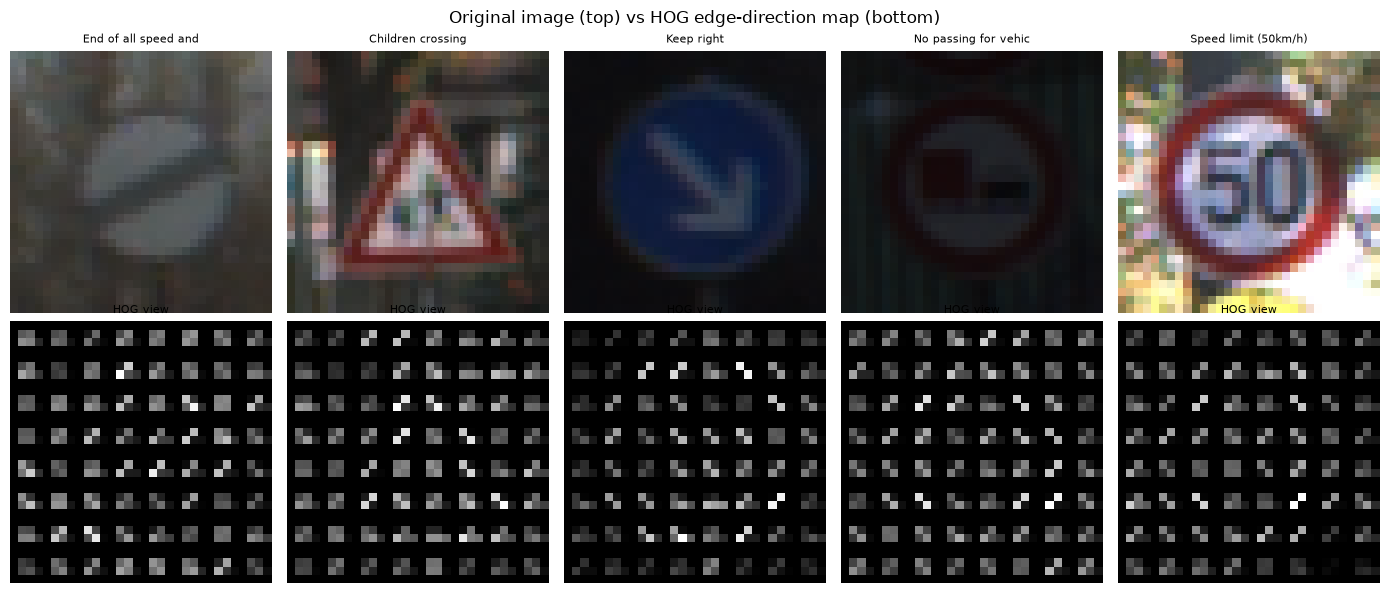

In [33]:
# Visualise what HOG "sees" for a few signs
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for j, idx in enumerate(np.random.choice(len(Xtr_img), 5, replace=False)):
    img = Xtr_img[idx]
    gray = exposure.equalize_adapthist(rgb2gray(img))
    _, hog_img = hog(gray, visualize=True, **HOG_PARAMS)
    axes[0, j].imshow(img);                axes[0, j].set_title(class_names[y_train[idx]][:20], fontsize=8)
    axes[1, j].imshow(hog_img, cmap="gray"); axes[1, j].set_title("HOG view", fontsize=8)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Original image (top) vs HOG edge-direction map (bottom)")
plt.tight_layout(); plt.show()

In [34]:
t0 = time.time()
F = {}   # F[feature_set] = (train, val, test)
for which in ["hog", "color", "hog+color"]:
    F[which] = (extract(Xtr_img, which), extract(Xva_img, which), extract(Xte_img, which))
print("Feature extraction time: %.1fs" % (time.time() - t0))
for k, v in F.items():
    print(f"{k:10s} -> {v[0].shape[1]} features per image")

hog+color: 100%|██████████| 12630/12630 [00:47<00:00, 265.77it/s]


Feature extraction time: 359.4s
hog        -> 1764 features per image
color      -> 24 features per image
hog+color  -> 1788 features per image


In [35]:
# Scaling (PCA)
USE_PCA = True
FITTED = {}   # remembers scaler + PCA 

def prepare(which):
    Xtr, Xva, Xte = F[which]
    sc = StandardScaler().fit(Xtr)
    Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    if USE_PCA:
        pca = PCA(n_components=0.95, random_state=42).fit(Xtr)
        Xtr, Xva, Xte = pca.transform(Xtr), pca.transform(Xva), pca.transform(Xte)
    FITTED[which] = (sc, pca if USE_PCA else None)
    return Xtr, Xva, Xte

Xtr, Xva, Xte = prepare("hog+color")
print("Features after scaling%s: %d" % (" + PCA" if USE_PCA else "", Xtr.shape[1]))

Features after scaling + PCA: 505


In [36]:
# Baseline SVM (RBF kernel)
t0 = time.time()
svm = SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")
svm.fit(Xtr, y_train)
print("Train time: %.1fs" % (time.time() - t0))
print("Baseline SVM  train acc: %.4f" % svm.score(Xtr, y_train))
print("Baseline SVM  val   acc: %.4f" % svm.score(Xva, y_val))

Train time: 133.9s
Baseline SVM  train acc: 1.0000
Baseline SVM  val   acc: 0.9004


In [37]:
# Hyper-parameter tuning track-wise (C and gamma)
n_feat = Xtr.shape[1]
gamma_scale = 1.0 / (n_feat * Xtr.var())     # what gamma="scale" means

results = []
for C in [1, 10, 50]:
    for mult in [0.5, 1, 2]:
        g = gamma_scale * mult
        t0 = time.time()
        m = SVC(kernel="rbf", C=C, gamma=g, class_weight="balanced").fit(Xtr, y_train)
        acc = m.score(Xva, y_val)
        results.append((C, mult, acc, time.time() - t0))
        print(f"C={C:<3} gamma=scale*{mult:<4} val acc={acc:.4f}  ({time.time()-t0:.0f}s)")

tune_df = pd.DataFrame(results, columns=["C", "gamma_mult", "val_acc", "sec"])
best = tune_df.sort_values("val_acc", ascending=False).iloc[0]
BEST_C, BEST_G = int(best.C), gamma_scale * best.gamma_mult
print("\nBest -> C=%d, gamma=scale*%.1f, val acc=%.4f" % (BEST_C, best.gamma_mult, best.val_acc))

display(tune_df.pivot(index="C", columns="gamma_mult", values="val_acc").round(4))

C=1   gamma=scale*0.5  val acc=0.9008  (198s)
C=1   gamma=scale*1    val acc=0.8976  (258s)
C=1   gamma=scale*2    val acc=0.8587  (456s)
C=10  gamma=scale*0.5  val acc=0.9057  (235s)
C=10  gamma=scale*1    val acc=0.9004  (263s)
C=10  gamma=scale*2    val acc=0.8658  (579s)
C=50  gamma=scale*0.5  val acc=0.9055  (198s)
C=50  gamma=scale*1    val acc=0.9004  (284s)
C=50  gamma=scale*2    val acc=0.8658  (360s)

Best -> C=10, gamma=scale*0.5, val acc=0.9057


gamma_mult,0.5,1.0,2.0
C,,,
1,0.9008,0.8976,0.8587
10,0.9057,0.9004,0.8658
50,0.9055,0.9004,0.8658


In [38]:
# Linear kernel vs RBF 
t0 = time.time()
lin = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42).fit(Xtr, y_train)
print("Linear SVM val acc: %.4f  (%.0fs)" % (lin.score(Xva, y_val), time.time() - t0))
print("RBF SVM    val acc: %.4f" % best.val_acc)

Linear SVM val acc: 0.8631  (70s)
RBF SVM    val acc: 0.9057


,Features,Val accuracy
0,color,0.138295
1,hog,0.896565
2,hog+color,0.900382


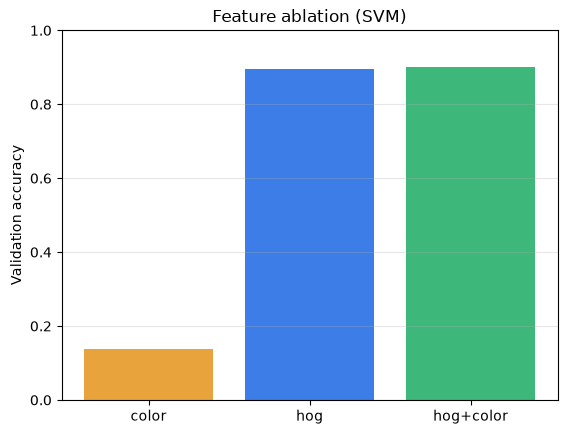

In [39]:
abl = []
for which in ["color", "hog", "hog+color"]:
    a, b, _ = prepare(which)
    m = SVC(kernel="rbf", C=BEST_C, gamma="scale", class_weight="balanced").fit(a, y_train)
    abl.append((which, m.score(b, y_val)))
abl_df = pd.DataFrame(abl, columns=["Features", "Val accuracy"])
display(abl_df)

plt.bar(abl_df["Features"], abl_df["Val accuracy"], color=["#E8A33D", "#3D7DE8", "#3DB87A"])
plt.ylim(0, 1); plt.ylabel("Validation accuracy"); plt.title("Feature ablation (SVM)")
plt.grid(axis="y", alpha=0.3); plt.show()

In [40]:
# Final Model 
t0 = time.time()
final_svm = SVC(kernel="rbf", C=BEST_C, gamma=BEST_G, class_weight="balanced").fit(Xtr, y_train)
svm_train_time = time.time() - t0

t0 = time.time()
pred_svm = final_svm.predict(Xte)
svm_pred_time = time.time() - t0

acc_svm = accuracy_score(y_test, pred_svm)
print("SVM (HOG + colour) TEST accuracy: %.4f" % acc_svm)
print("Train time %.0fs | Predict time for %d images: %.1fs" % (svm_train_time, len(Xte), svm_pred_time))
print("Misclassified: %d / %d" % ((pred_svm != y_test).sum(), len(y_test)))

SVM (HOG + colour) TEST accuracy: 0.8964
Train time 52s | Predict time for 12630 images: 108.6s
Misclassified: 1308 / 12630


In [41]:
print(classification_report(y_test, pred_svm, target_names=class_names, digits=3))

                                             precision    recall  f1-score   support

                       Speed limit (20km/h)      0.918     0.750     0.826        60
                       Speed limit (30km/h)      0.863     0.854     0.858       720
                       Speed limit (50km/h)      0.780     0.863     0.820       750
                       Speed limit (60km/h)      0.899     0.756     0.821       450
                       Speed limit (70km/h)      0.961     0.939     0.950       660
                       Speed limit (80km/h)      0.709     0.805     0.754       630
                End of speed limit (80km/h)      0.982     0.740     0.844       150
                      Speed limit (100km/h)      0.874     0.851     0.863       450
                      Speed limit (120km/h)      0.823     0.849     0.836       450
                                 No passing      0.923     0.969     0.945       480
      No passing for vehicles over 3.5 tons      0.974     0.958

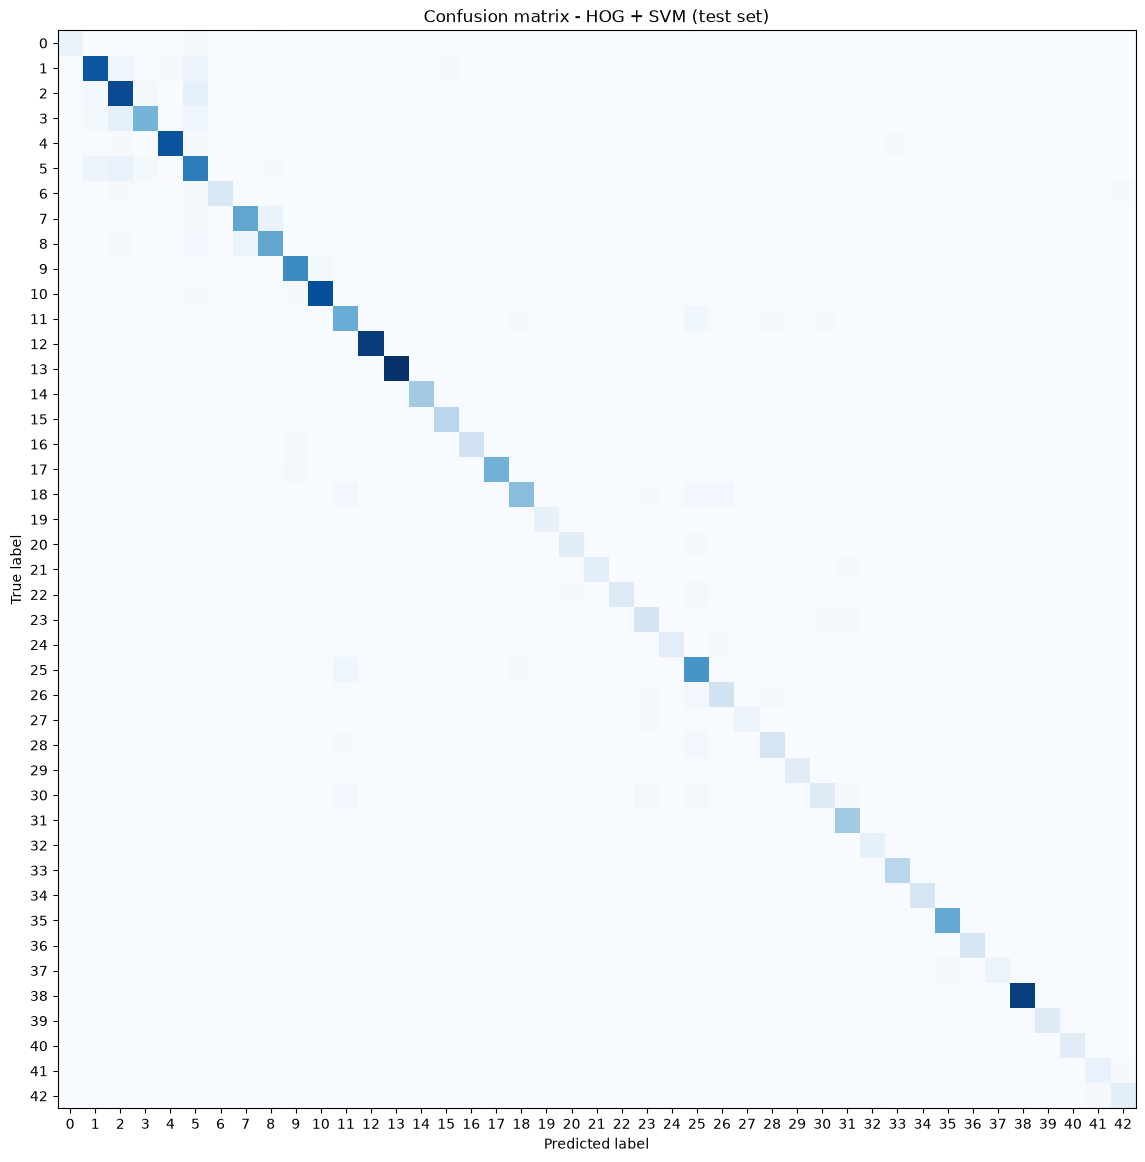

,Class,Accuracy,Test images
30,Beware of ice/snow,0.587,150
37,Go straight or left,0.650,60
27,Pedestrians,0.667,60
6,End of speed limit (80km/h),0.740,150
0,Speed limit (20km/h),0.750,60
26,Traffic signals,0.750,180
22,Bumpy road,0.750,120
3,Speed limit (60km/h),0.756,450


In [42]:
cm_svm = confusion_matrix(y_test, pred_svm)
fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay(cm_svm).plot(ax=ax, cmap="Blues", colorbar=False, include_values=False)
ax.set_title("Confusion matrix - HOG + SVM (test set)")
plt.show()

# Weakest classes
per_class = cm_svm.diagonal() / cm_svm.sum(axis=1)
weak_svm = pd.DataFrame({"Class": class_names, "Accuracy": per_class,
                     "Test images": cm_svm.sum(axis=1)}).sort_values("Accuracy").head(8)
display(weak_svm.round(3))

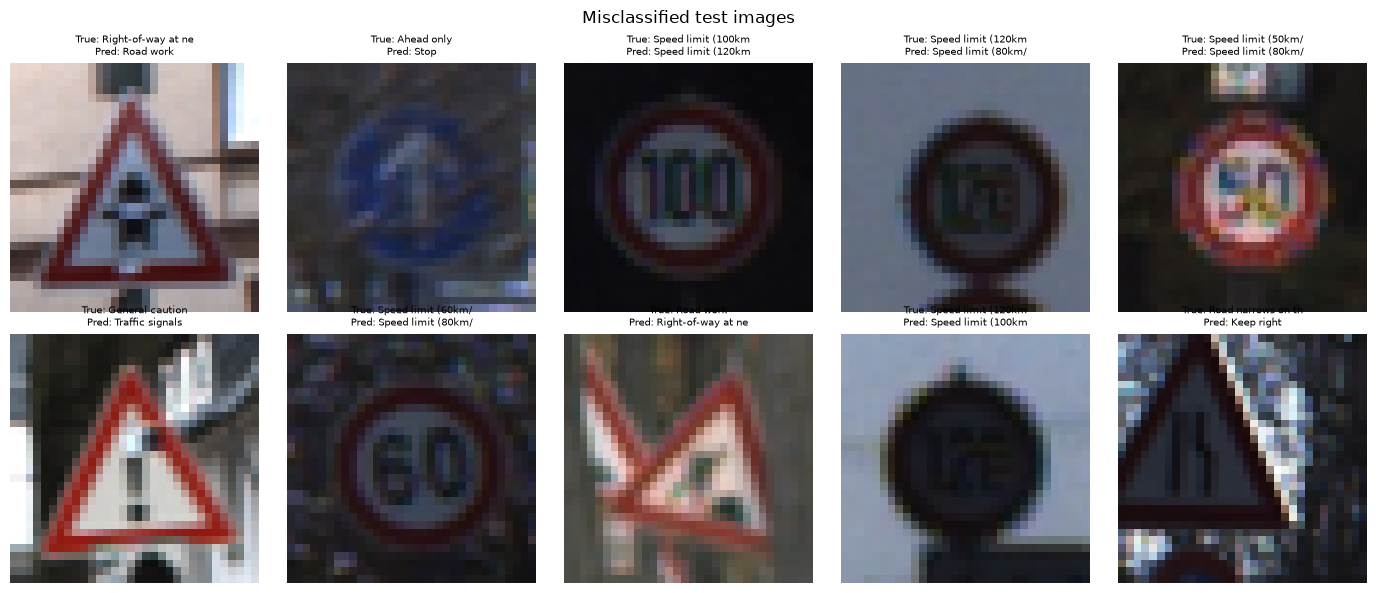

In [43]:
# Wrongly predicted examples
wrong = np.where(pred_svm != y_test)[0]
plt.figure(figsize=(14, 6))
for k, idx in enumerate(np.random.choice(wrong, min(10, len(wrong)), replace=False)):
    plt.subplot(2, 5, k + 1)
    plt.imshow(Xte_img[idx]); plt.axis("off")
    plt.title("True: %s\nPred: %s" % (class_names[y_test[idx]][:18], class_names[pred_svm[idx]][:18]),
              fontsize=7)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

### Final comparison: ANN vs ML (SVM) vs CNN

,Model,Test accuracy
0,ANN (raw pixels),83.17 %
1,ML: HOG + colour + SVM,89.64 %
2,CNN,96.01 %


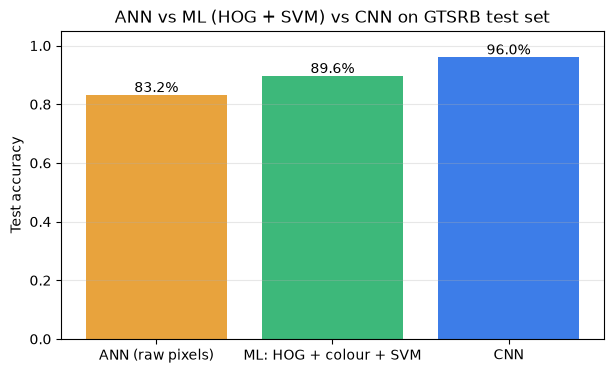

In [44]:
# ---- Final comparison: ANN vs ML (SVM) vs CNN ----
# the earlier cells of this notebook (ANN-vs-CNN table and the SVM TEST accuracy).
import pandas as pd
import matplotlib.pyplot as plt

try:
    acc_ann, acc_cnn, acc_svm
except NameError:
    acc_ann, acc_cnn, acc_svm = 0.8302, 0.9474, 0.8964

comp3 = pd.DataFrame({
    "Model": ["ANN (raw pixels)", "ML: HOG + colour + SVM", "CNN"],
    "Test accuracy": [acc_ann, acc_svm, acc_cnn],
})
comp3_show = comp3.copy()
comp3_show["Test accuracy"] = (comp3_show["Test accuracy"] * 100).round(2).astype(str) + " %"
display(comp3_show)

plt.figure(figsize=(7, 4))
bars = plt.bar(comp3["Model"], comp3["Test accuracy"], color=["#E8A33D", "#3DB87A", "#3D7DE8"])
for b, v in zip(bars, comp3["Test accuracy"]):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center")
plt.ylim(0, 1.05); plt.ylabel("Test accuracy")
plt.title("ANN vs ML (HOG + SVM) vs CNN on GTSRB test set")
plt.grid(axis="y", alpha=0.3); plt.show()

### Save the ML model (optional)

In [45]:
# Best parameters from tuning: C=10, gamma = scale * 0.5
n_feat = Xtr.shape[1]
gamma_scale = 1.0 / (n_feat * Xtr.var())
BEST_C, BEST_G = 10, gamma_scale * 0.5

final_svm = SVC(kernel="rbf", C=BEST_C, gamma=BEST_G, class_weight="balanced").fit(Xtr, y_train)
print("Validation accuracy:", round(final_svm.score(Xva, y_val), 4))   # should be about 0.9057

import joblib
sc, pca = FITTED["hog+color"]
joblib.dump({"scaler": sc, "pca": pca, "svm": final_svm, "class_names": class_names},
            "traffic_sign_svm.joblib")
print("Saved: traffic_sign_svm.joblib")

Validation accuracy: 0.9057
Saved: traffic_sign_svm.joblib
